# TG_NLDAS2_WY2012 fSCA sweep: snow cover fraction by scheme

Compares the snow-covered fraction of the ground (`FSNO`) over Tony Grove, UT, for one
snow season (WY2012: 1 Oct 2011 to 30 Jun 2012), at the Tony Grove RS SNOTEL station, across the `snow_fsca_param` schemes run by
`run_scripts/testing/sweep_fsca.sh`. All variants are clones of the base case
`TG_NLDAS2_WY2012_lastmods` and use its executable, so they differ only in the fSCA scheme.

**Output.** `TG_NLDAS2_WY20XX.sh` sets `hist_nhtfrq = -24` and `hist_mfilt = 365`, so each
variant has one h0 file of daily means, in `$OUTPUT_ROOT/<case>_<variant>/run/`.

Model SWE is compared with the station's observed SWE, loaded with the `model_datasets`
package (`../model_data_loader`), which reads the PNNL bias-corrected, quality-controlled
SNOTEL data set. Model fSCA is compared with MODSCAG satellite fSCA on the same 0.125° grid.

For now only CZ26, SL12 and NY07 are loaded (see `VARIANTS` below).

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd
import xarray as xr
from dotenv import find_dotenv, load_dotenv
from model_datasets.snotel import PNNLSnotel

BASE = "TG_NLDAS2_WY2012_lastmods"
VARIANTS = ["CZ26", "SL12", "NY07"]   # add AR25 etc. here once those runs are sorted out
START = "2011-10-01"                  # first day of the history file name
END = "2012-06-30"                    # last day of the run
SITE_NAME = "Tony Grove RS"           # SNOTEL site name as in the PNNL summary file

# Paths come from the .env file in the repo root (found by searching up from here)
env_file = find_dotenv(usecwd=True)
if not env_file:
    raise FileNotFoundError("No .env file found in this directory or above it")
load_dotenv(env_file, override=True)
OUTPUT_ROOT = Path(os.environ["OUTPUT_ROOT"])   # model output, one folder per case
# Local copy of the fsurdat file used by the runs (the run script's surfdataFile)
SURFDATA_FILE = Path(os.environ["DATA_ROOT"]) / "surfdata_TG_UT_0125_c261028_merged.nc"
# PNNL SNOTEL data: holds SNOTEL_Detre.csv and bcqc_data_v2/
SNOTEL_PATH = os.environ["SNOTEL_PATH"]
# STC-MODSCAG daily fSCA on the 0.125 deg WUS grid, one file per calendar year
MODSCAG_PATH = Path(os.environ["MODSCAG_PATH"])

## Load the data

`open_history` opens one variant's h0 file. ELM writes a record at step 0 (the first
half-hour time step), which isn't a daily mean, so it is dropped. Each record's time stamp
is the *end* of its averaging interval (e.g. the 1 Oct mean is stamped 2 Oct 00:00), so the
times are moved to the interval midpoints from `time_bounds`. ELM uses a `noleap` calendar;
converting to `datetime64` makes plotting easier and is safe for these dates (there is no
29 Feb in the noleap calendar, so 29 Feb 2012 is simply missing).

The grid cells' elevation comes from `TOPO` in the surface data file, not from the history
file's `topo`, which is the atmosphere's surface height from the coupler; DATM leaves it at
0 m. The surface data file is on dimensions `lsmlat, lsmlon`, the same 12 × 8 grid as the
history files.

In [2]:
def open_history(variant):
    case = f"{BASE}_{variant}"
    f = OUTPUT_ROOT / case / "run" / f"{case}.elm.h0.{START}-00000.nc"
    ds = xr.open_dataset(f)
    ds = ds.isel(time=slice(1, None))            # drop the step-0 record
    t0, t1 = ds["time_bounds"].values.T          # cftime objects
    ds = ds.assign_coords(time=t0 + (t1 - t0) / 2)
    return ds.convert_calendar("standard", use_cftime=False)

runs = {v: open_history(v) for v in VARIANTS}
for v, ds in runs.items():
    print(f"{v}: {ds.sizes['time']} days, {ds.time.values[0]} .. {ds.time.values[-1]}, "
          f"grid {ds.sizes['lat']} x {ds.sizes['lon']}")

ref = runs[VARIANTS[0]]
surf = xr.open_dataset(SURFDATA_FILE)
# Check that the surfdata grid lines up with the history grid before relabeling it
assert (abs(surf["LATIXY"].isel(lsmlon=0).values - ref.lat.values).max() < 1e-4 and
        abs(surf["LONGXY"].isel(lsmlat=0).values - ref.lon.values).max() < 1e-4)
topo = xr.DataArray(surf["TOPO"].values, coords={"lat": ref.lat, "lon": ref.lon})

CZ26: 273 days, 2011-10-01T12:00:00.000000000 .. 2012-06-30T12:00:00.000000000, grid 12 x 8
SL12: 273 days, 2011-10-01T12:00:00.000000000 .. 2012-06-30T12:00:00.000000000, grid 12 x 8
NY07: 273 days, 2011-10-01T12:00:00.000000000 .. 2012-06-30T12:00:00.000000000, grid 12 x 8


## SNOTEL observations at Tony Grove RS

`PNNLSnotel` looks up the site in the PNNL summary file and uses the more precise location
from `SNOTEL_Detre.csv` when there is one. `load_data()` then reads the daily record and
converts it to metric units (`swe_mm`, `precip_mm`, `T_*_C`). Its index is local time
(America/Denver); the time zone is dropped here so that it lines up with the model dates.

The model grid cell is the one whose 0.125° box contains the station (`method="nearest"`
on the cell centers). ELM's history longitudes run 0–360°, so the station's longitude is
shifted to match.

In [3]:
site = PNNLSnotel(SITE_NAME, storage_path=SNOTEL_PATH)
site.load_data()
obs = site.data.loc[START:END].copy()
obs.index = obs.index.tz_localize(None)

near = dict(lat=site.latitude, lon=site.longitude % 360, method="nearest")
cell = topo.sel(**near)
print(f"{SITE_NAME}: {site.latitude:.4f}N, {site.longitude:.4f}E, {site.elevation:.0f} m "
      f"(precise location: {site.precise_location})")
print(f"nearest cell: {float(cell.lat):.4f}N, {float(cell.lon) - 360:.4f}E, "
      f"mean elevation {float(cell):.0f} m")
print(f"obs: {len(obs)} days, {obs['swe_mm'].isna().sum()} missing SWE, "
      f"peak SWE {obs['swe_mm'].max():.0f} mm on {obs['swe_mm'].idxmax():%d %b %Y}")

Tony Grove RS: 41.8857N, -111.5693E, 1928 m (precise location: True)
nearest cell: 41.9375N, -111.5625E, mean elevation 1856 m
obs: 274 days, 0 missing SWE, peak SWE 297 mm on 07 Mar 2012


## MODSCAG fSCA at Tony Grove RS

STC-MODSCAG is daily fractional snow cover from MODIS. It is "spatially and temporally
complete" (STC), meaning cloud gaps and missing days are filled, so the series has no
missing values. The files are already on the 0.125° grid, with 0–360° longitudes, so the
same `near` selection picks the same cell as the model; the code checks that.

There's one file per calendar year, so a water year needs two files. Only the station's
cell is read from each file, which is fast and doesn't need dask.

Note: `FSNO` in these files is in **percent** (0–100), although its `units` attribute says
`1`, so it is divided by 100 here (as in `../fSCA/notebooks/output_analysis.ipynb`). If the
files are missing, the plot below leaves MODSCAG out.

In [4]:
years = range(int(START[:4]), int(END[:4]) + 1)
modscag_files = [MODSCAG_PATH / f"WUS_Snow_Daily_{y}_MODSCAG.nc" for y in years]
missing = [f.name for f in modscag_files if not f.exists()]
if missing:
    modscag = None
    print(f"MODSCAG: not plotted, missing {', '.join(missing)} in {MODSCAG_PATH}")
else:
    modscag = xr.concat([xr.open_dataset(f)["FSNO"].sel(**near) for f in modscag_files],
                        dim="time").sel(time=slice(START, END)).load() / 100
    assert abs(float(modscag.lat) - float(cell.lat)) < 1e-4
    assert abs(float(modscag.lon) - float(cell.lon)) < 1e-4
    print(f"MODSCAG: {modscag.sizes['time']} days, "
          f"{int(modscag.isnull().sum())} missing, max {float(modscag.max()):.2f}")

MODSCAG: not plotted, missing WUS_Snow_Daily_2011_MODSCAG.nc, WUS_Snow_Daily_2012_MODSCAG.nc in /home/chris/Science/data/MODSCAG-STC/0125deg


## fSCA and SWE at Tony Grove RS

Top: `FSNO`, the daily-mean fraction of the ground covered by snow, in the cell nearest the
station. MODSCAG fSCA for the same cell is in black.

Bottom: SWE. The model's `H2OSNO` (mm of liquid water) is the snow water of the whole cell,
including any snow-free part, so when `FSNO` < 1 it's lower than the SWE under the snow.
SNOTEL measures a single point under continuous snow. The model also stands for a whole cell
whose mean elevation can differ from the station's (see above). The SNOTEL value is a
once-daily reading and the model value is a daily mean over a UTC day, so the two can be up
to a day apart. That doesn't matter at this time scale.

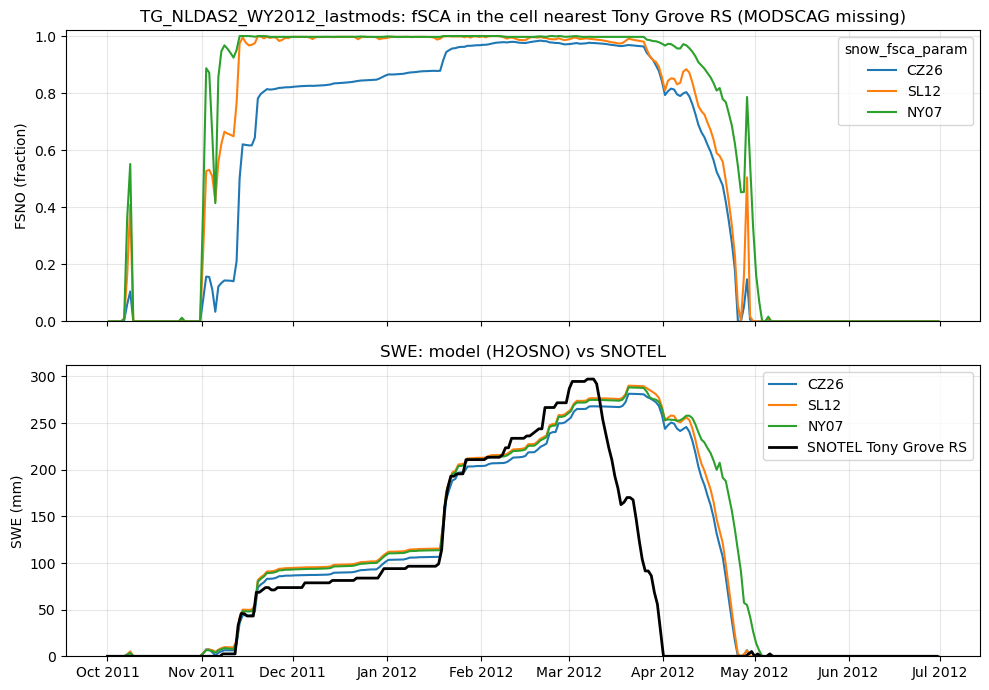

In [8]:
fig, (ax_f, ax_s) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
for v, ds in runs.items():
    pt = ds.sel(**near)
    pt["FSNO"].plot(ax=ax_f, label=v)
    pt["H2OSNO"].plot(ax=ax_s, label=v)
if modscag is not None:
    ax_f.plot(modscag.time, modscag, color="k", lw=2, label="MODSCAG")
ax_s.plot(obs.index, obs["swe_mm"], color="k", lw=2, label=f"SNOTEL {SITE_NAME}")

ax_f.set(title=f"{BASE}: fSCA in the cell nearest {SITE_NAME}"
               + ("" if modscag is not None else " (MODSCAG missing)"),
         xlabel="", ylabel="FSNO (fraction)", ylim=(0, 1.02))
ax_f.legend(title="snow_fsca_param")
ax_s.set(title="SWE: model (H2OSNO) vs SNOTEL", xlabel="", ylabel="SWE (mm)", ylim=(0, None))
ax_s.legend()
for ax in (ax_f, ax_s):
    ax.grid(alpha=0.3)
ax_s.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.tight_layout()
plt.show()

## fsca package vs the model, same algorithm

The next cells run algorithms from the `fsca` package (`../fSCA/src/fsca/algorithms/`) on the
model's own daily SWE (`H2OSNO`) in the station's cell. Each result is compared with `FSNO`
from the run that used the same scheme. They should be similar but not identical:

- **Time step.** ELM updates fSCA every 30-minute step from that step's new snow
  (`newsnow`) and SWE, and `FSNO` is the daily mean of those values. The package steps
  once a day on daily-mean SWE, so it sees only the net daily change: a day with both
  snowfall and melt looks like a smaller accumulation or a smaller melt. In both, any step
  without new snow moves fSCA down the depletion curve, including SWE lost to sublimation.
- **Same terrain input.** ELM passes the gridcell's `fsca_stddev_elev` from the surface
  data file to both SL12 and CZ26 as `sigma_elev`, so that's the `sigma` used here.

**Which code ran.** The history files' `source_id` attribute gives the E3SM commit that
was built: `6bf6a17237` ("Add AR25 option fSCA algorithm", on `origin/fsca`). The schemes
are in `components/elm/src/biogeophys/SnowCoverFractionMod.F90` at that commit, and they
differ from `origin/ez/fsca`. Check against that commit, e.g.
`git -C ../E3SM show 6bf6a17237:components/elm/src/biogeophys/SnowCoverFractionMod.F90`.

The package classes are imported directly. `fsca.grid_calc` is for the gridded runs, and
it needs `SWANN_PATH` and `FSCA_OUTPUT_PATH` set when it is imported. Each class keeps its
state (`W`, `Wmax`, `fSCA`) between calls, so `calc_fsca(swe, depth, date)` is called once
per day, in order. `SNOWDP` is passed as the depth, which SL12 and CZ26 don't use.

In [9]:
from fsca.algorithms.sl12 import fSCA_SL12
from fsca.algorithms.cz26v3 import fSCA_CZ26v3

for v, ds in runs.items():
    print(f"{v}: built from E3SM {ds.attrs['source_id']}")

# fsca_stddev_elev on the history grid, like `topo` (the grids were checked to match above)
sigma = float(xr.DataArray(surf["fsca_stddev_elev"].values,
                           coords={"lat": ref.lat, "lon": ref.lon}).sel(**near))
print(f"fsca_stddev_elev in the {SITE_NAME} cell: {sigma:.0f} m")


def run_daily(calculator, variant):
    """Run a package fSCA calculator on one variant's daily H2OSNO in the station's cell."""
    pt = runs[variant].sel(**near)
    dates = pd.DatetimeIndex(pt.time.values)
    fsca = [calculator.calc_fsca(float(swe), float(hs), d)
            for swe, hs, d in zip(pt["H2OSNO"].values, pt["SNOWDP"].values, dates)]
    return pt["FSNO"], xr.DataArray(fsca, coords={"time": pt.time}, name="fSCA")


def plot_pkg_vs_model(model, pkg, label):
    """Plot model FSNO and package fSCA, with their difference below."""
    diff = pkg - model
    print(f"{label}, package - model: mean {float(diff.mean()):+.3f}, "
          f"RMSE {float((diff**2).mean()**0.5):.3f}, max |diff| {float(abs(diff).max()):.3f}")

    fig, (ax_f, ax_d) = plt.subplots(2, 1, figsize=(10, 6), sharex=True,
                                     gridspec_kw={"height_ratios": [2, 1]})
    model.plot(ax=ax_f, label=f"ELM {label} (FSNO, 30-min steps, daily mean)")
    pkg.plot(ax=ax_f, ls="--", label=f"fsca package {label} (daily H2OSNO)")
    ax_f.set(title=f"{label} fSCA in the cell nearest {SITE_NAME}: model vs fsca package",
             xlabel="", ylabel="fSCA (fraction)", ylim=(0, 1.02))
    ax_f.legend()
    diff.plot(ax=ax_d, color="0.3")
    ax_d.axhline(0, color="k", lw=0.8)
    ax_d.set(title="package − model", xlabel="", ylabel="Δ fSCA")
    for ax in (ax_f, ax_d):
        ax.grid(alpha=0.3)
    ax_d.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    plt.tight_layout()
    plt.show()

CZ26: built from E3SM 6bf6a17237
SL12: built from E3SM 6bf6a17237
NY07: built from E3SM 6bf6a17237
fsca_stddev_elev in the Tony Grove RS cell: 175 m


### SL12

ELM (`fsca_SL12_update`) and the package (`sl12.py`) both use the SL12 depletion curve
`1 - (acos(2W/Wmax - 1)/π)^Nmelt`, with `Wmax` recomputed after each accumulation so that
fSCA stays continuous. Two differences:

- **Nmelt.** ELM uses `200 / max(10, σ)`; the package uses `200 / max(1, σ)`. This only
  matters where σ < 10 m.
- **Accumulation.** ELM uses `1 - (1 - tanh(0.1·newsnow))(1 - fSCA)` each step. The package
  defaults to `1 - (1 - min(1, 0.1·ΔW))(1 - fSCA)`. These are almost the same for small
  snowfalls, but the linear form saturates sooner for big storms.

SL12: Nmelt = 1.142, k = 0.1, tanh_accum = False
SL12, package - model: mean +0.006, RMSE 0.017, max |diff| 0.153


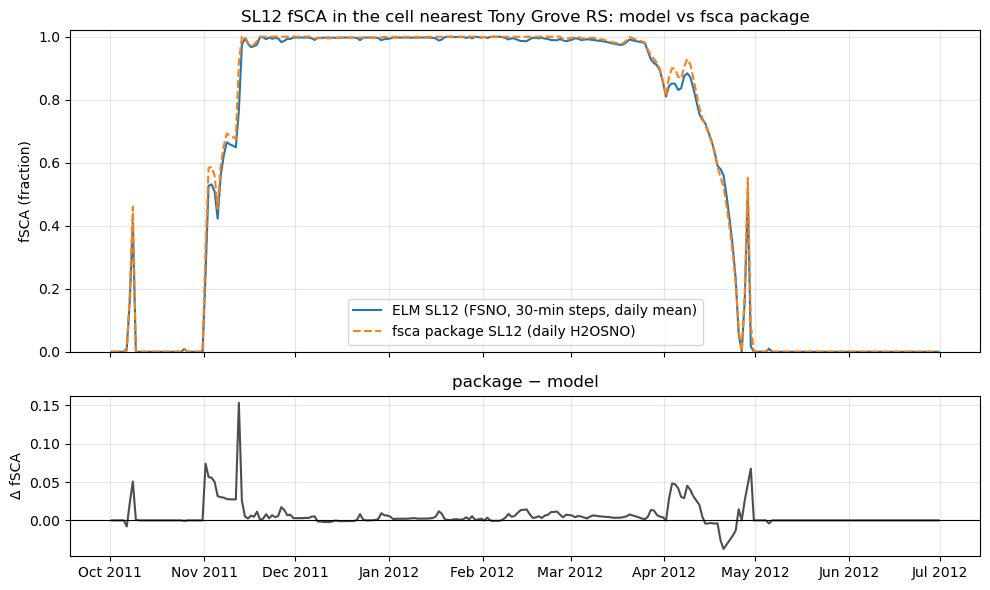

In [10]:
sl12 = fSCA_SL12(sigma=sigma)   # default k = 0.1, tanh_accum = False
print(f"SL12: Nmelt = {sl12.Nmelt:.3f}, k = {sl12.k}, tanh_accum = {sl12.tanh_accum}")
plot_pkg_vs_model(*run_daily(sl12, "SL12"), "SL12")

### CZ26

ELM's CZ26 (`fsca_CZ26_update`) is a port of the package's `cz26v3.py` with
`melt_param='sigma'` and `alpha_zero=False`, the class defaults. The footprint
`S = A·tanh(b·ΔW)`, the overlap α table, the σ and fSCA bins, and
`Nmelt = 200 / max(σ, 10)` are the same in both.

The footprint and α were fitted to **daily** SWE increments (`cz26_alpha_storm.ipynb`).
The package applies them to daily increments, as they were fitted, but ELM applies them
to each 30-minute `newsnow`. A storm spread over many steps therefore gives a different
result in ELM. With `S = A·tanh(b·ΔW)` and overlap with the cover it has just built,
splitting one day's snowfall into many small steps gives a different total footprint than
one daily step.

CZ26: Nmelt = 1.142, footprint A = 0.338069, b = 0.109163, alpha by F_n bin = [0.       0.774635 0.437692 0.16632  0.13128  0.387584 0.670587]
CZ26, package - model: mean -0.023, RMSE 0.038, max |diff| 0.097


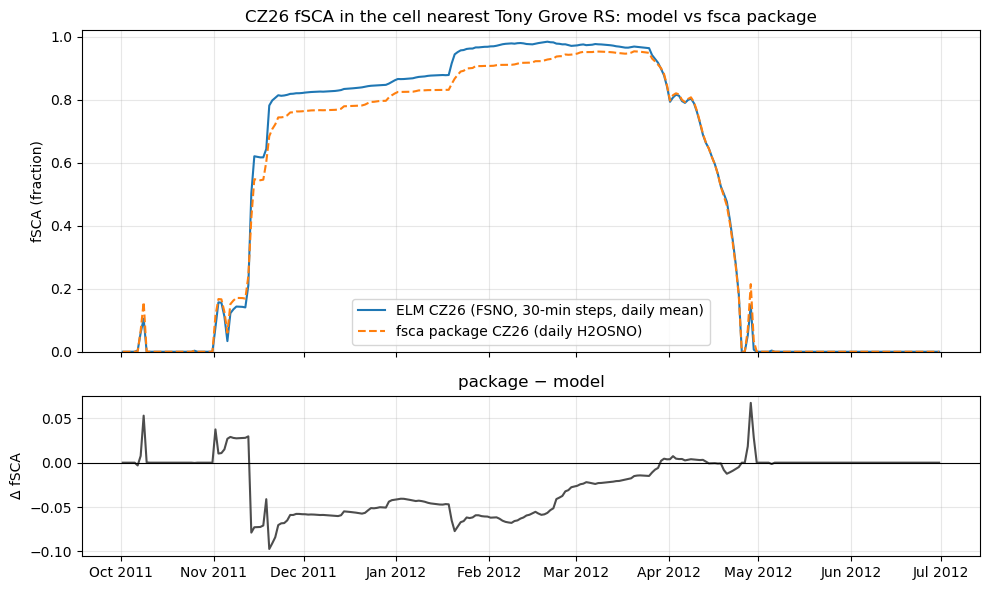

In [11]:
# mu is only used when melt_param is 'mu' or 'mu_star', so it isn't needed here
cz26 = fSCA_CZ26v3(sigma=sigma, mu=None)   # defaults: melt_param='sigma', alpha_zero=False
print(f"CZ26: Nmelt = {cz26.Nmelt:.3f}, footprint A = {cz26.A}, b = {cz26.b}, "
      f"alpha by F_n bin = {cz26.alpha_col}")
plot_pkg_vs_model(*run_daily(cz26, "CZ26"), "CZ26")